In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from math import pi
import time

from sklearn.metrics import roc_auc_score, accuracy_score
from sklearn.preprocessing import MinMaxScaler
from qiskit import QuantumCircuit
from qiskit import QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit.circuit.library import efficient_su2, real_amplitudes, pauli_two_design
from qiskit_machine_learning.neural_networks import SamplerQNN, EstimatorQNN
# from qiskit.primitives import StatevectorSampler as Sampler
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals
from IPython.display import clear_output

import tensorflow as tf
from keras import layers

algorithm_globals.random_seed = 42

C:\Users\Rohan\miniconda3\envs\qae\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\Rohan\miniconda3\envs\qae\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\Rohan\miniconda3\envs\qae\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/resource_handle.proto. Please update the gencode to avoid

In [23]:
from qiskit.circuit import QuantumCircuit, ParameterVector
from qiskit.circuit.library import EfficientSU2, RealAmplitudes
import numpy as np

def angle_encoding(x):
    num_qubits = len(x)
    circuit = QuantumCircuit(num_qubits)
    for i in range(num_qubits):
        circuit.ry(x[i], i)
    return circuit

def dense_angle_encoding(x):
    num_qubits = len(x) // 2
    circuit = QuantumCircuit(num_qubits)
    for i in range(num_qubits):
        circuit.ry(x[2 * i], i)
        circuit.rz(x[2 * i + 1], i)
    return circuit

def efficient_su2_encoding(x):
    num_qubits = int(np.ceil(len(x) / 4))  # EfficientSU2 expects 4 params per qubit per rep
    su2 = EfficientSU2(num_qubits=num_qubits, reps=3)

    # Pad x to match the number of parameters in EfficientSU2
    total_params = su2.num_parameters
    padded_x = np.pad(x, (0, total_params - len(x)), mode='constant')

    circuit = QuantumCircuit(num_qubits)
    circuit.compose(su2.assign_parameters(padded_x), inplace=True)
    return circuit

def amplitude_encoding(x):

    x = np.asarray(x, dtype=np.float64)

    # Replace NaNs and Infs with 0 BEFORE padding
    if not np.all(np.isfinite(x)):
        x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)

    # Pad first
    num_qubits = int(np.ceil(np.log2(len(x))))
    target_len = 2 ** num_qubits
    padded = np.pad(x, (0, target_len - len(x))).astype(np.float64)

    # Normalize
    norm = np.linalg.norm(padded)
    if norm == 0 or not np.isfinite(norm):
        # Default to |0⟩ state if invalid
        normalized = np.zeros_like(padded)
        normalized[0] = 1.0
    else:
        normalized = padded / norm

    # Safety check (this ensures Qiskit won't throw)
    assert np.isclose(np.sum(normalized**2), 1.0, atol=1e-10), f"Vector not normalized: {np.sum(normalized**2)}"

    # Create circuit
    circuit = QuantumCircuit(num_qubits)
    circuit.initialize(normalized, range(num_qubits))
    return circuit


def build_encoded_circuits(data, encoding_fn):
    circuits = []
    for x in data:
        circuit = encoding_fn(x)
        circuits.append(circuit)
    return circuits

def ansatz(num_qubits):
    # return real_amplitudes(num_qubits, reps=1)
    return pauli_two_design(num_qubits, reps=1)

def auto_encoder_circuit(num_latent, num_trash):
    qr = QuantumRegister(num_latent + 2 * num_trash + 1, "q")
    cr = ClassicalRegister(1, "c")
    circuit = QuantumCircuit(qr, cr)
    circuit.compose(ansatz(num_latent + num_trash), range(0, num_latent + num_trash), inplace=True)
    circuit.barrier()
    auxiliary_qubit = num_latent + 2 * num_trash
    # swap test
    circuit.h(auxiliary_qubit)
    for i in range(num_trash):
        circuit.cswap(auxiliary_qubit, num_latent + i, num_latent + num_trash + i)

    circuit.h(auxiliary_qubit)
    circuit.measure(auxiliary_qubit, cr[0])
    return circuit

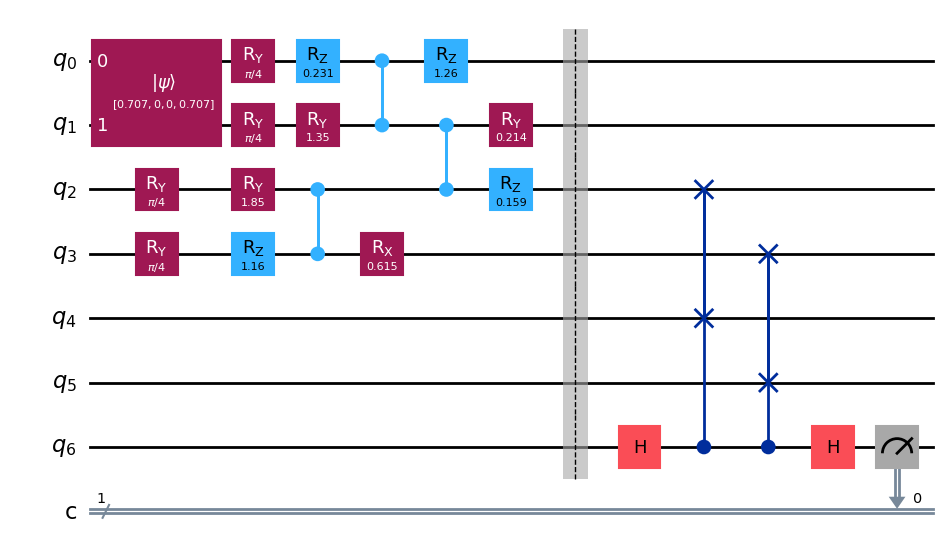

In [34]:
from numpy import sqrt
from qiskit.qpy import load

# Constants
num_latent = 2
num_trash = 2
total_qubits = num_latent + 2 * num_trash + 1  # encoding + reference + auxiliary

# Create Circuit
# ae = auto_encoder_circuit(num_latent, num_trash)

# Generate some random values to bind to the AE parameters
# param_values = np.random.uniform(0, 2 * np.pi, len(ae.parameters))
# ae = ae.assign_parameters({p: v for p, v in zip(ae.parameters, param_values)})

model_name = "Models/COBLYA_AEs/8f_qae_dense_pauli_v2"
trained_params = np.load(f"{model_name}/trained_parameters.npy")
with open(f"{model_name}/ae.qpy", "rb") as f:
    ae = load(f)[0]  # returns a list of circuits
ae = ae.assign_parameters({p: v for p, v in zip(ae.parameters, trained_params)})

# State Prep
vec = [sqrt(0.5), 0, 0, sqrt(0.5)]  # For 2 qubits (like |00⟩ + |11⟩)
Statevector(vec).draw('latex')  # Visualize

# QC Init
encoding = QuantumCircuit(total_qubits)
encoding.initialize(vec, [0, 1])  # Targeting qubit 0 and 1

qc_full = encoding.compose(ae)
qc_full.draw('mpl') 


In [11]:
from qiskit_aer import AerSimulator
# -- Simulate statevector
sim = AerSimulator(method='statevector')
qc_full.save_statevector()
result = sim.run(qc_full).result()
state = result.get_statevector()

# Print statevector
print(state)

Statevector([ 0.00000000e+00+0.00000000e+00j,
              0.00000000e+00+0.00000000e+00j,
             -0.00000000e+00+0.00000000e+00j,
              0.00000000e+00+0.00000000e+00j,
             -0.00000000e+00+0.00000000e+00j,
              0.00000000e+00+0.00000000e+00j,
             -0.00000000e+00+0.00000000e+00j,
             -0.00000000e+00+0.00000000e+00j,
              0.00000000e+00+0.00000000e+00j,
              0.00000000e+00+0.00000000e+00j,
             -0.00000000e+00+0.00000000e+00j,
              0.00000000e+00+0.00000000e+00j,
             -0.00000000e+00+0.00000000e+00j,
              0.00000000e+00+0.00000000e+00j,
             -0.00000000e+00+0.00000000e+00j,
             -0.00000000e+00+0.00000000e+00j,
             -0.00000000e+00+0.00000000e+00j,
              0.00000000e+00+0.00000000e+00j,
             -0.00000000e+00+0.00000000e+00j,
             -0.00000000e+00+0.00000000e+00j,
              0.00000000e+00+0.00000000e+00j,
              0.00000000e+00+0.000